# 论文图的外观编辑教程

### 用 `sp.interactive` 改图，数据不动，代码可复现

一张实证论文里的图，往往要改十几遍外观。期刊要求的字体和字号、合作者想换的配色、审稿人嫌太小的刻度标签。直接改 matplotlib 有两个风险。一是不小心动到数据，比如把纵轴范围收紧，置信区间被裁掉一截却没有任何提示。二是改完之后说不清改了什么，下次重画又得从头再来。

`sp.interactive` 是 StatsPAI 的图形编辑器，思路和 Stata 的 Graph Editor 一样，但多了三条保证。

1. **数据锁定。** 点估计、拟合线、误差线、置信带、柱子只能改样式，不能被移走、裁掉或调成看不见。
2. **代码可复现。** 每一步编辑都生成一段 matplotlib 代码，接在画图代码后面运行，得到的图和编辑结果逐像素相同。
3. **撤销精确。** `undo()` 和 `reset()` 回到的就是原来那张图。

这三条都由测试逐像素检查，覆盖每一种编辑操作和 StatsPAI 的每一个画图函数。

| 节 | 内容 |
| --- | --- |
| 1 | 画一张事件研究图 |
| 2 | 编辑器怎样认出「数据」 |
| 3 | 一次调用完成编辑 |
| 4 | 数据保护是怎么起作用的 |
| 5 | 按系列改色，图例跟着变 |
| 6 | 可复现的代码 |
| 7 | 撤销与重置 |
| 8 | 投稿前检查与导出 |
| 9 | 把一套样式用到另一张图上 |
| 10 | 在 Jupyter 里用面板编辑 |
| 11 | 小结 |

In [1]:
import os
import tempfile
import warnings

warnings.filterwarnings("ignore")  # 教程里隐藏无关提示；编辑器自己的提示会在下面单独打印

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statspai as sp

plt.rcParams["figure.dpi"] = 80
print("StatsPAI 版本:", sp.__version__)

StatsPAI 版本: 1.39.6


## 1. 画一张事件研究图

用随包自带的最低工资面板 `mpdta`，跑 Callaway-Sant'Anna 估计，画动态效应图。注意，包里的 `mpdta` 是按原数据结构生成的模拟副本，下面的数字只用来演示画图，不是对真实数据的结论。

后面要反复「重新画一张一模一样的图」，所以把画图写成一个函数。

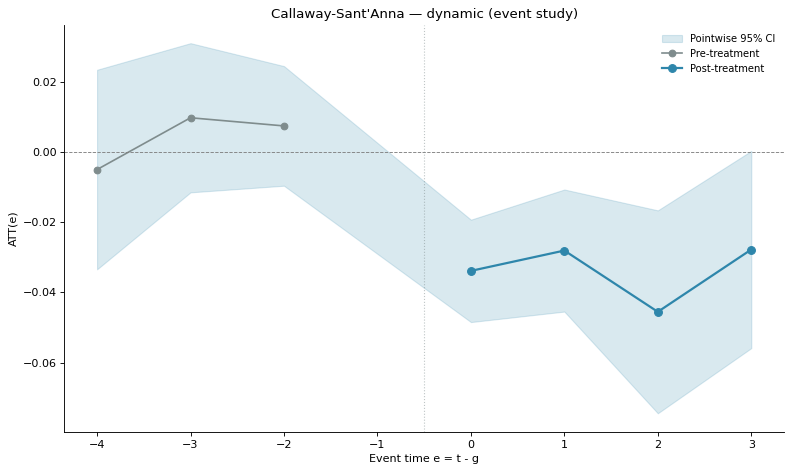

In [2]:
mp = sp.datasets.mpdta()
gt = sp.callaway_santanna(data=mp, y="lemp", t="year", i="countyreal", g="first_treat")
dyn = sp.aggte(gt, type="dynamic", bstrap=False)


def draw():
    fig, ax = sp.ggdid(dyn)
    plt.close(fig)  # 只在需要时显示
    return fig


fig = draw()
fig

### 图里的置信带是什么？

`sp.ggdid` 画出的阴影是每个事件时间 $e$ 上 ATT 的**逐点** 95% 置信区间，即 $\widehat{ATT}(e) \pm 1.96\,\mathrm{se}(e)$。`bstrap=False` 表示标准误用影响函数的解析公式计算，不做自助法，所以每次运行的结果都一样。

逐点的意思是每个区间单独有 95% 的覆盖率。图上有 7 个事件时间，7 个区间**同时**覆盖真值的概率一般低于 95%。要对整条曲线下结论，比如「处理后每一期的效应都为负」，需要一致置信带（uniform band），它把 1.96 换成一个更大的临界值。

```python
dyn_u = sp.aggte(gt, type="dynamic", cband=True, n_boot=1000, random_state=0)
```

这样会用乘子自助法（multiplier bootstrap）算出临界值，`sp.ggdid(dyn_u)` 会在逐点区间外面再画一层一致置信带。本例的临界值是 2.56，换成种子 1 和 2 分别是 2.68 和 2.55，自助法带有模拟误差。

| $e$ | ATT | 逐点 95% 区间（本图） | 一致 95% 带 |
| --- | --- | --- | --- |
| 0 | -0.0338 | [-0.0485, -0.0192] | [-0.0532, -0.0145] |
| 1 | -0.0280 | [-0.0455, -0.0106] | [-0.0516, -0.0044] |
| 2 | -0.0455 | [-0.0745, -0.0166] | [-0.0839, -0.0072] |
| 3 | -0.0277 | [-0.0559, 0.0004] | [-0.0630, 0.0075] |

- 横轴上没有 $e=-1$。默认 `base_period="universal"` 把每个队列处理前的一期 $g-1$ 当作基期，这一期的效应按定义为 0，不画出来。
- 一致带用的是自助法标准误，与解析标准误略有差别，所以它不是逐点区间简单放大 2.56/1.96 倍。

## 2. 编辑器怎样认出「数据」

编辑器打开时，会给图里的每个元素分一个角色。`DATA`（点估计、数据线、柱子）、`FIT`（拟合线）、`CI`（误差线和置信带）这三类是锁定的。参考线（零线、处理时点的竖线）、标题、坐标轴、图例、文字注释可以随便改。

判断的依据有三条。errorbar、柱状图这类元素，matplotlib 自己记录了哪些部分属于同一组数据，编辑器直接读这份记录。一条线算不算参考线，只看几何形状（水平或竖直），不看标签，所以一条叫「Treatment group」的数据线不会被误放开。认不出来的元素一律锁定。

In [3]:
ed = sp.plots.FigureEditor(fig)
ax = fig.axes[0]
rows = []
for kind, artists in [("line", ax.get_lines()), ("collection", ax.collections), ("patch", ax.patches)]:
    for j, a in enumerate(artists):
        rows.append({
            "元素": f"{kind}{j}",
            "类型": type(a).__name__,
            "标签": a.get_label(),
            "角色": ed.artist_roles[id(a)].name,
        })
pd.DataFrame(rows)

,元素,类型,标签,角色
0,line0,Line2D,Pre-treatment,DATA
1,line1,Line2D,Post-treatment,DATA
2,line2,Line2D,_child3,REFERENCE
3,line3,Line2D,_child4,REFERENCE
4,collection0,FillBetweenPolyCollection,Pointwise 95% CI,CI


## 3. 一次调用完成编辑

在脚本、服务器或者 agent 里没有界面，可以把编辑写成一个列表交给 `sp.interactive`。每一项是一个操作名加上它的参数，`FigureEditor.operations()` 列出了全部操作。

下面这组编辑改了标题和两个坐标轴标签，套用 AER 风格的主题，把图设成整页宽（6.5 英寸），最后整理一次边距。

StatsPAI figure editor: 6 edit(s)
  1. set_title: {'text': 'Minimum wage and teen employment', 'ax_index': 0}
  2. set_ylabel: {'text': 'ATT on log employment', 'ax_index': 0}
  3. set_xlabel: {'text': 'Years since the minimum wage rose', 'ax_index': 0}
  4. apply_theme: {'theme': 'aea', 'recolor': True}
  5. set_figsize: {'width': 6.5, 'height': 4.0}
  6. tight_layout: {}


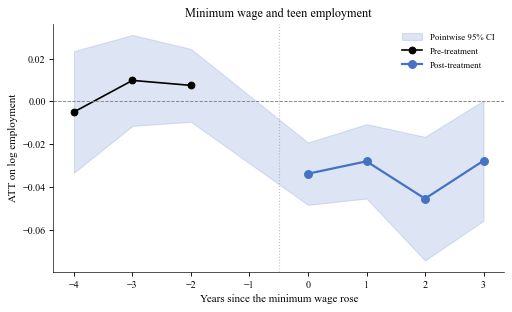

In [4]:
fig = draw()
editor = sp.interactive(
    fig,
    ui="none",
    actions=[
        {"action": "set_title", "text": "Minimum wage and teen employment"},
        {"action": "set_ylabel", "text": "ATT on log employment"},
        {"action": "set_xlabel", "text": "Years since the minimum wage rose"},
        {"action": "apply_theme", "theme": "aea"},
        {"action": "set_figsize", "width": 6.5, "height": 4.0},
        {"action": "tight_layout"},
    ],
)
print(editor.summary())
fig

## 4. 数据保护是怎么起作用的

假设想把纵轴收紧到 $[-0.02, 0.02]$，让图看起来更「紧凑」。置信带的范围大约是 −0.075 到 0.031，这样收紧会把大部分区间裁掉。编辑器不会照做，它把范围放宽到能装下所有点、误差线和置信带，再留 2% 的边，并给出提示。

提示: Axis limits [-0.02, 0.02] would hide data, error bars or confidence bands spanning [-0.0745, 0.03118]. Expanded to [-0.07661, 0.0333].
实际的纵轴范围: (np.float64(-0.0766), np.float64(0.0333))


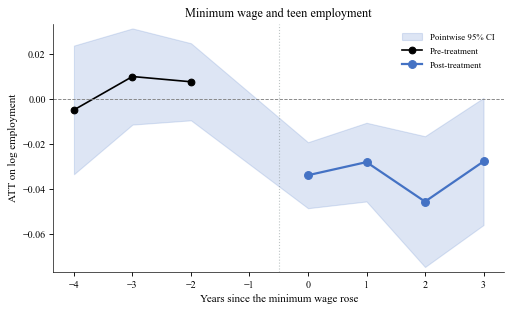

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    editor.set_ylim(-0.02, 0.02)
for w in caught:
    print("提示:", w.message)
print("实际的纵轴范围:", tuple(round(v, 4) for v in fig.axes[0].get_ylim()))
fig

同样，数据不能被调成看不见。透明度设到 0 会被抬到下限（点和线 0.2，置信带 0.05）；把一条只有点、没有连线的序列的标记去掉，会直接报错。被拒绝的编辑不会留下任何改动。

In [6]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    editor.set_alpha("line0", 0.0)
print("提示:", caught[0].message)
editor.undo()

try:
    editor.set_linestyle(0, "None")
    editor.set_marker(0, "None")
except ValueError as exc:
    print("拒绝:", str(exc).splitlines()[0])
editor.undo()  # 撤销上面那步改线型

提示: alpha=0.0 would make a locked DATA element nearly invisible; using 0.2.
拒绝: set_marker: this would make a locked DATA line invisible (no line and no markers). Data stays visible while protect_data=True.


## 5. 按系列改色，图例跟着变

同一个系列的点估计、连线和置信带通常是同一种颜色。编辑器按颜色把锁定的元素分成「系列」，改色时整组一起换。matplotlib 的图例保存的是创建时的样子，直接改线的颜色，图例会停在旧颜色，读者就会把系列对错。编辑器每次改色之后都会重建图例。

`okabe_ito` 是一套常用的色盲友好配色。

系列 0: 颜色 #7f8c8d，包含 1 个元素
系列 1: 颜色 #2e86ab，包含 2 个元素


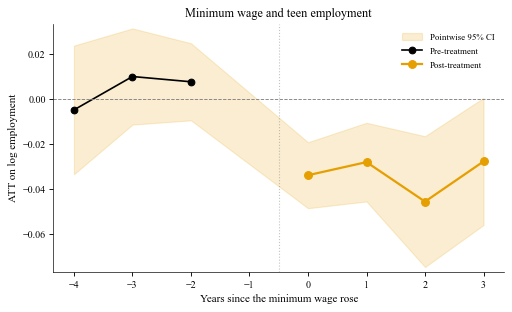

In [7]:
for g, group in enumerate(editor.color_groups(0)):
    print(f"系列 {g}: 颜色 {group['color']}，包含 {len(group['members'])} 个元素")
editor.apply_palette("okabe_ito")
fig

## 6. 可复现的代码

`generate_code()` 给出的代码只需要变量 `fig`，接在画图代码后面运行即可。同一个属性改了多次的，只保留最后一次。下面在一张新画的图上运行这段代码，再和编辑后的图逐像素比较。

In [8]:
code = editor.generate_code()
print(code)

# --- StatsPAI figure edits (run after the code that draws `fig`) ---
import statspai as sp
ax = fig.axes[0]
ax.title.set_text('Minimum wage and teen employment')
ax.set_ylabel('ATT on log employment')
ax.set_xlabel('Years since the minimum wage rose')
# theme 'aea'
fig.set_facecolor('#ffffff')
ax.set_facecolor('#ffffff')
for _name, _vis in {'top': False, 'right': False, 'bottom': True, 'left': True}.items():
    ax.spines[_name].set_visible(_vis)
    ax.spines[_name].set_linewidth(0.6)
    ax.spines[_name].set_edgecolor('#000000')
ax.set_axisbelow('line')
ax.grid(False)
ax.title.set_fontsize(11.0)
ax.title.set_fontweight('normal')
ax.title.set_color('#000000')
for _lab in (ax.xaxis.label, ax.yaxis.label):
    _lab.set_fontsize(10.0)
    _lab.set_fontweight('normal')
    _lab.set_color('#000000')
ax.tick_params(axis='x', which='both', labelsize=9.0, direction='out', color='#000000', labelcolor='#000000')
ax.tick_params(axis='y', which='both', labelsize=9.0, direction='out', color='#000

In [9]:
def pixels(f):
    f.canvas.draw()
    return np.asarray(f.canvas.buffer_rgba()).copy()


fresh = draw()
exec(code, {"fig": fresh})
print("新图运行代码后与编辑结果逐像素相同:", np.array_equal(pixels(fresh), pixels(fig)))

新图运行代码后与编辑结果逐像素相同: True


## 7. 撤销与重置

每一步编辑之前，编辑器都会记下相关元素的完整状态，所以撤销回到的是编辑前的那张图，而不是近似。`reset()` 撤销全部编辑。

In [10]:
original = pixels(draw())
n_edits = len(editor.edits)
editor.reset()
print(f"撤销了 {n_edits} 步编辑；与原图逐像素相同:", np.array_equal(pixels(fig), original))

撤销了 8 步编辑；与原图逐像素相同: True


## 8. 投稿前检查与导出

`check()` 按印刷时的尺寸检查三件事：小于 6 磅的文字，黑白打印时分不清的系列（亮度接近、线型和标记也相同），以及和背景几乎同色的系列。

`save()` 默认把 TrueType 字体嵌进 PDF。matplotlib 默认输出 Type 3 字体，不少投稿系统会拒收。

下面先把图缩到一栏宽，并故意把刻度字号设得太小。

In [11]:
fig = draw()
editor = sp.interactive(fig, ui="none")
editor.set_figsize(3.5, 2.6)        # 一栏宽度
editor.set_fontsize("ticks", 5)     # 故意设得太小
for finding in editor.check():
    print(finding["code"], "|", finding["message"])

font_too_small | Text at 5.0 pt is below 6.0 pt at the current figure size; journals usually ask for 6-8 pt at print size.
grayscale_collision | Series drawn in #7f8c8d and #2e86ab look the same in black and white (and share line style and marker); change one colour, line style or marker.


In [12]:
editor.set_fontsize("ticks", 7)
editor.set_fontsize("xlabel", 8)
editor.set_fontsize("ylabel", 8)
editor.set_fontsize("title", 8)
editor.set_fontsize("legend", 6.5)
for finding in editor.check():
    print(finding["code"], "|", finding["message"])

grayscale_collision | Series drawn in #7f8c8d and #2e86ab look the same in black and white (and share line style and marker); change one colour, line style or marker.


字号问题解决了，但还剩一条。处理前的灰色和处理后的蓝色亮度接近，线型和标记也一样，印成黑白就分不出哪段是处理前。换一套亮度差别大的配色，再查一遍。

检查结果: 没有问题


嵌入 TrueType 字体: True | 含 Type 3 字体: False


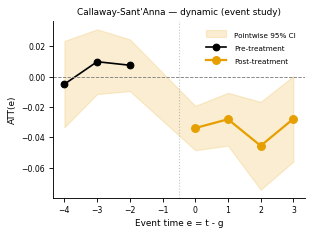

In [13]:
editor.apply_palette("okabe_ito")
print("检查结果:", editor.check() or "没有问题")

path = os.path.join(tempfile.mkdtemp(), "figure1.pdf")
editor.save(path)
pdf = open(path, "rb").read()
print("嵌入 TrueType 字体:", b"/FontFile2" in pdf, "| 含 Type 3 字体:", b"/Type3" in pdf)
fig

## 9. 把一套样式用到另一张图上

调好的样式可以保存成 JSON，用到别的图上，作用类似 Stata Graph Editor 的 recording。新图里没有的元素（比如少一条线）会被跳过并给出提示。

下面把同一套样式用到「尚未处理单位作对照」的估计结果上。

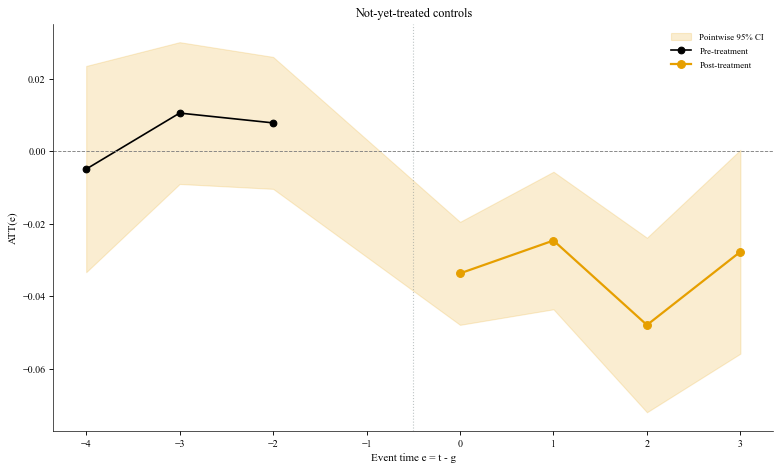

In [14]:
fig = draw()
editor = sp.interactive(fig, ui="none", actions=[
    {"action": "set_title", "text": "Never-treated controls"},
    {"action": "apply_theme", "theme": "aea"},
    {"action": "apply_palette", "palette": "okabe_ito"},
])
style = editor.to_edits_json()

gt_nyt = sp.callaway_santanna(data=mp, y="lemp", t="year", i="countyreal",
                              g="first_treat", control_group="notyettreated")
fig2, _ = sp.ggdid(sp.aggte(gt_nyt, type="dynamic", bstrap=False))
plt.close(fig2)
other = sp.interactive(fig2, ui="none")
other.apply_edits_json(style)
other.set_title("Not-yet-treated controls")
fig2

In [15]:
# Create an interactive figure
# sp.interactive(fig2)

## 10. 在 Jupyter 里用面板编辑

在 notebook 里直接调用 `sp.interactive(fig)`，会在图的右边打开一个面板，左边是实时预览。面板有五个标签页。

- **Theme**：主题和调色板。
- **Text**：标题、坐标轴标签、字号、字体预设。
- **Style**：按系列改色，以及每条线的颜色、线宽、线型、标记、透明度。
- **Layout**：边框、网格、图的尺寸、背景、图例（含条目改名）、刻度标签旋转、坐标范围、文字注释。
- **Export**：保存文件、投稿前检查、可复现代码、撤销重做、保存和套用样式。

面板需要 `pip install ipywidgets`。如果 JupyterLab 里只显示一行 `HBox(children=...)` 文字，说明前端没有加载 widgets 扩展，处理办法见 `docs/guides/figure_editor.md` 的 Troubleshooting 一节。静态的 notebook 显示不出面板，所以这一节只写出调用方式。

```python
fig, ax = sp.ggdid(dyn)
editor = sp.interactive(fig)      # 打开面板
print(editor.generate_code())     # 编辑结束后取出代码
```

在 Qt、Tk、macOS 这类图形窗口后端下，`sp.interactive(fig)` 会在图旁边打开一个小的控制窗口，点一下标题或坐标轴标签就能改字。

## 11. 小结

改论文图时可以照着下面的顺序做。

1. **先把尺寸定成印刷尺寸。** 一栏约 3.5 英寸，整页宽约 6.5 英寸。字号是在这个尺寸下的磅数。
2. **用主题和调色板统一风格**（`apply_theme`、`apply_palette`），系列要按组改色。
3. **收紧坐标轴之前看一眼提示。** 被放宽说明原来的范围会遮住数据。
4. **运行 `check()`**，再用 `save()` 导出嵌入字体的 PDF。
5. **把 `generate_code()` 的代码放进复现材料**，或者把样式存成 JSON 用到其他图上。

完整说明见 `docs/guides/figure_editor.md`。

In [16]:
keys = ["callaway2021difference"]
print(sp.bibtex(keys))

@article{callaway2021difference,
  title={Difference-in-Differences with Multiple Time Periods},
  author={Callaway, Brantly and Sant'Anna, Pedro H. C.},
  journal={Journal of Econometrics},
  volume={225},
  number={2},
  pages={200--230},
  year={2021},
  publisher={Elsevier},
  doi={10.1016/j.jeconom.2020.12.001}
}
